# Лабораторная работа №2

Train: (50000, 32, 32, 3) (50000,)
Test:  (10000, 32, 32, 3) (10000,)


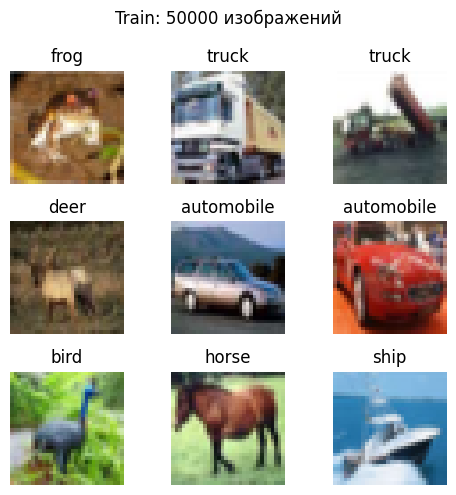

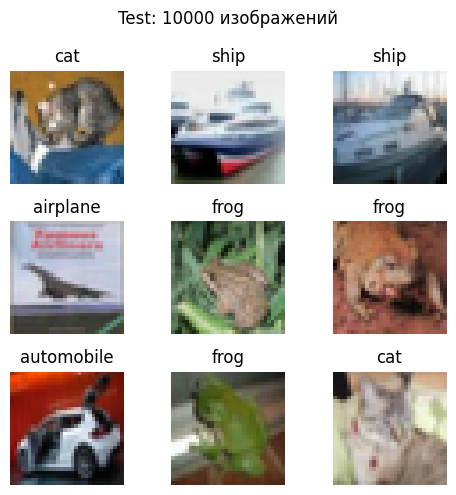

In [1]:
import time
from collections.abc import Iterator
from math import ceil

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from numpy import typing as npt

torch.manual_seed(42)
np.random.seed(42)

CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
DATA_ROOT = "./"


# ---------- Загрузка данных ----------

raw_train = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True, download=True)
raw_test = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=False, download=True)

train_images = raw_train.data
train_labels = np.array(raw_train.targets)
test_images = raw_test.data
test_labels = np.array(raw_test.targets)

print("Train:", train_images.shape, train_labels.shape)
print("Test: ", test_images.shape, test_labels.shape)


# ---------- Визуализация выборок ----------

def show_images(images: npt.NDArray[np.uint8], labels: npt.NDArray[np.int64], title: str) -> None:
    """Сетка 3x3 из первых изображений выборки с подписями классов."""
    fig, axes = plt.subplots(3, 3, figsize=(5, 5))
    fig.suptitle(title)
    for i, ax in enumerate(axes.flat):
        ax.imshow(images[i])
        ax.set_title(CLASSES[labels[i]])
        ax.axis("off")
    plt.tight_layout()
    plt.show()


show_images(train_images, train_labels, f"Train: {len(train_images)} изображений")
show_images(test_images, test_labels, f"Test: {len(test_images)} изображений")

Устройство: cpu
Гиперпараметры: lr = 0.00125, размер пачки = 128, эпох = 20, ширина = 16
x_train: (50000, 3, 32, 32) | x_test: (10000, 3, 32, 32)
Параметров в сети: 413514
Эпоха  1/20 | кросс-энтропия: 1.5770 | ошибка на train: 56.55% | точность на train: 43.45% | ошибка на test: 49.36% | время: 49.86 с
Эпоха  2/20 | кросс-энтропия: 1.0953 | ошибка на train: 39.06% | точность на train: 60.94% | ошибка на test: 36.51% | время: 53.56 с
Эпоха  3/20 | кросс-энтропия: 0.9144 | ошибка на train: 31.87% | точность на train: 68.13% | ошибка на test: 33.25% | время: 54.69 с
Эпоха  4/20 | кросс-энтропия: 0.7910 | ошибка на train: 27.30% | точность на train: 72.70% | ошибка на test: 26.92% | время: 54.57 с
Эпоха  5/20 | кросс-энтропия: 0.6979 | ошибка на train: 23.84% | точность на train: 76.16% | ошибка на test: 23.90% | время: 55.58 с
Эпоха  6/20 | кросс-энтропия: 0.6409 | ошибка на train: 21.81% | точность на train: 78.19% | ошибка на test: 25.99% | время: 54.56 с
Эпоха  7/20 | кросс-энтропия: 

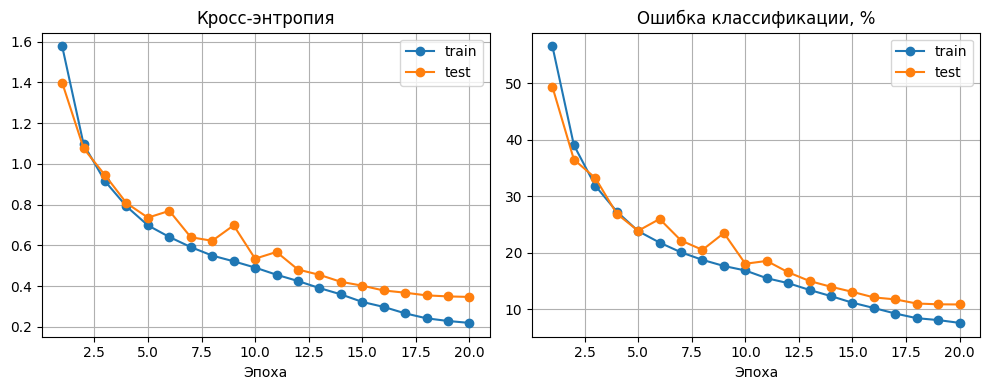

In [2]:
# ---------- Гиперпараметры и устройство ----------

BATCH_SIZE = 128
EVAL_BATCH_SIZE = 1000
EPOCHS = 20
LEARNING_RATE = 0.00125
WEIGHT_DECAY = 1e-4
WIDTH = 16  # число каналов первого слоя, остальные слои кратны ему

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", DEVICE)
print(f"Гиперпараметры: lr = {LEARNING_RATE}, размер пачки = {BATCH_SIZE}, эпох = {EPOCHS}, ширина = {WIDTH}")


# ---------- Предобработка ----------

def compute_stats(images: npt.NDArray[np.uint8]) -> tuple[list[float], list[float]]:
    """Среднее и стандартное отклонение по каналам (изображения в диапазоне [0, 1])."""
    mean = images.mean(axis=(0, 1, 2)) / 255.0
    std = images.std(axis=(0, 1, 2)) / 255.0
    return mean.tolist(), std.tolist()


def to_tensor(images: npt.NDArray[np.uint8], mean: list[float], std: list[float]) -> torch.Tensor:
    """Весь набор сразу в нормализованный тензор (N, 3, 32, 32): без PIL и DataLoader, так быстрее."""
    x = torch.from_numpy(images).permute(0, 3, 1, 2).float() / 255.0
    mean_t = torch.tensor(mean).view(1, 3, 1, 1)
    std_t = torch.tensor(std).view(1, 3, 1, 1)
    return ((x - mean_t) / std_t).contiguous()


# Статистику считаем по train и применяем к обеим выборкам
mean, std = compute_stats(train_images)

x_train = to_tensor(train_images, mean, std).to(DEVICE)
x_test = to_tensor(test_images, mean, std).to(DEVICE)
y_train = torch.from_numpy(train_labels).long().to(DEVICE)
y_test = torch.from_numpy(test_labels).long().to(DEVICE)

STEPS_PER_EPOCH = ceil(len(x_train) / BATCH_SIZE)
print("x_train:", tuple(x_train.shape), "| x_test:", tuple(x_test.shape))


def iterate_batches(
    x: torch.Tensor, y: torch.Tensor, batch_size: int, shuffle: bool
) -> Iterator[tuple[torch.Tensor, torch.Tensor]]:
    """Пачки из тензоров в памяти; при shuffle порядок примеров случайный."""
    order = torch.randperm(len(x), device=x.device) if shuffle else torch.arange(len(x), device=x.device)
    for start in range(0, len(x), batch_size):
        idx = order[start:start + batch_size]
        yield x[idx], y[idx]


def augment(x: torch.Tensor) -> torch.Tensor:
    """Аугментация пачки: отражение по горизонтали и случайный сдвиг (RandomCrop с отступом 4)."""
    n = x.size(0)
    flip = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip.view(-1, 1, 1, 1), x.flip(3), x)
    padded = F.pad(x, (4, 4, 4, 4))
    shifts = torch.randint(0, 9, (n, 2)).tolist()
    return torch.stack([padded[i, :, dy:dy + 32, dx:dx + 32] for i, (dy, dx) in enumerate(shifts)])


# ---------- Архитектура (ResNet-подобная сеть) ----------

def conv_block(n_in: int, n_out: int, pool: bool = False) -> nn.Sequential:
    """Свёртка 3x3 + BatchNorm + ReLU, при необходимости с MaxPool 2x2."""
    layers = [
        nn.Conv2d(n_in, n_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(n_out),
        nn.ReLU(inplace=True),
    ]
    if pool:
        layers.append(nn.MaxPool2d(kernel_size=2))
    return nn.Sequential(*layers)


class ResNetNetwork(nn.Module):
    """Свёрточная сеть с двумя остаточными блоками (skip-connection)."""

    def __init__(self, width: int) -> None:
        super().__init__()
        self.conv1 = conv_block(3, width)
        self.conv_and_pool_1 = conv_block(width, 2 * width, pool=True)
        self.res1 = nn.Sequential(conv_block(2 * width, 2 * width), conv_block(2 * width, 2 * width))
        self.conv_and_pool_2 = conv_block(2 * width, 4 * width, pool=True)
        self.conv_and_pool_3 = conv_block(4 * width, 8 * width, pool=True)
        self.res2 = nn.Sequential(conv_block(8 * width, 8 * width), conv_block(8 * width, 8 * width))
        self.final_pool = nn.MaxPool2d(kernel_size=4)
        self.dense = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(8 * width, 10),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.conv1(x)
        out = self.conv_and_pool_1(out)
        out = self.res1(out) + out
        out = self.conv_and_pool_2(out)
        out = self.conv_and_pool_3(out)
        out = self.res2(out) + out
        out = self.final_pool(out)
        return self.dense(out)


model = ResNetNetwork(WIDTH).to(DEVICE)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LEARNING_RATE * 8, epochs=EPOCHS, steps_per_epoch=STEPS_PER_EPOCH
)

print("Параметров в сети:", sum(p.numel() for p in model.parameters()))


# ---------- Метрики ----------

def evaluate(net: nn.Module, x: torch.Tensor, y: torch.Tensor) -> tuple[float, float]:
    """Средняя кросс-энтропия и доля ошибок классификации на всём наборе."""
    net.eval()
    total_loss = torch.zeros((), device=DEVICE)
    wrong = torch.zeros((), device=DEVICE)
    with torch.inference_mode():
        for images, labels in iterate_batches(x, y, EVAL_BATCH_SIZE, shuffle=False):
            outputs = net(images)
            total_loss += loss_function(outputs, labels) * labels.size(0)
            wrong += (outputs.argmax(dim=1) != labels).sum()
    return total_loss.item() / len(x), wrong.item() / len(x)


# ---------- Обучение ----------

def train(net: nn.Module) -> dict[str, list[float]]:
    """Ошибка на train считается по ходу эпохи (на аугментированных данных), без отдельного прохода."""
    history = {"loss": [], "err": [], "test_loss": [], "test_err": [], "time": []}

    for epoch in range(1, EPOCHS + 1):
        start_time = time.time()
        net.train()
        total_loss = torch.zeros((), device=DEVICE)
        wrong = torch.zeros((), device=DEVICE)

        for images, labels in iterate_batches(x_train, y_train, BATCH_SIZE, shuffle=True):
            outputs = net(augment(images))
            loss = loss_function(outputs, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()

            total_loss += loss.detach() * labels.size(0)
            wrong += (outputs.argmax(dim=1) != labels).sum()

        loss, err = total_loss.item() / len(x_train), wrong.item() / len(x_train)
        elapsed = time.time() - start_time

        test_loss, test_err = evaluate(net, x_test, y_test)
        for key, value in zip(history, (loss, err, test_loss, test_err, elapsed)):
            history[key].append(value)

        print(
            f"Эпоха {epoch:2d}/{EPOCHS} | "
            f"кросс-энтропия: {loss:.4f} | "
            f"ошибка на train: {err:.2%} | "
            f"точность на train: {1 - err:.2%} | "
            f"ошибка на test: {test_err:.2%} | "
            f"время: {elapsed:.2f} с"
        )

    print(f"\nОшибка на тесте: {test_err:.2%} | Точность: {1 - test_err:.2%}")
    print(f"Суммарное время обучения: {sum(history['time']):.2f} с")
    return history


history = train(model)


# ---------- Визуализация ----------

epochs_axis = range(1, EPOCHS + 1)
fig, (ax_loss, ax_err) = plt.subplots(1, 2, figsize=(10, 4))

ax_loss.plot(epochs_axis, history["loss"], marker="o", label="train")
ax_loss.plot(epochs_axis, history["test_loss"], marker="o", label="test")
ax_loss.set_title("Кросс-энтропия")
ax_loss.set_xlabel("Эпоха")
ax_loss.legend()
ax_loss.grid(True)

ax_err.plot(epochs_axis, [e * 100 for e in history["err"]], marker="o", label="train")
ax_err.plot(epochs_axis, [e * 100 for e in history["test_err"]], marker="o", label="test")
ax_err.set_title("Ошибка классификации, %")
ax_err.set_xlabel("Эпоха")
ax_err.legend()
ax_err.grid(True)

plt.tight_layout()
plt.show()